In [2]:
from sklearn.datasets import fetch_openml
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score,f1_score,recall_score,precision_score
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.dummy import DummyClassifier

In [3]:
mnist=fetch_openml('mnist_784', as_frame=False)

In [4]:
X,y=mnist.data,mnist.target

In [5]:
#train test split
X_train,y_train,X_test,y_test=X[:60000],y[:60000],X[60000:],y[60000:]

In [6]:
#training a binary classifier
#X_train ->is 5 or not&
#donc y est true or false
y_train_5=(y_train=='5')
y_train_5

array([ True, False, False, ...,  True, False, False])

In [7]:
y_test_5=(y_test=='5')

In [8]:
#etape 1 :entrainer le modele
clf=SGDClassifier(random_state=42)#SGDCclassifier commence par des poids aleatoires et puis il les teawk pour minimier l'erreur ->alea=random_state
clf.fit(X_train,y_train_5)

,"loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [9]:
#etape 2 :faire les predictions
y_train_pred=clf.predict(X_train)
y_test_pred=clf.predict(X_test)

In [10]:
#etape3:evaluation
accuracy_train=accuracy_score(y_train_5,y_train_pred)
accuracy_test=accuracy_score(y_test_5,y_test_pred)

In [11]:
print(accuracy_train)
print(accuracy_test) #test > train

0.9522666666666667
0.9492


In [12]:
scores=cross_val_score(clf,X_test,y_test_5,cv=5,scoring="accuracy")
scores

array([0.939 , 0.95  , 0.9645, 0.9625, 0.972 ])

In [13]:
print(scores.mean())
print(scores.std())

0.9576
0.01168503316212669


In [14]:
dummy_clf=DummyClassifier()
dummy_clf.fit(X_train,y_train_5)


,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'prior'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None


In [15]:
print(any(dummy_clf.predict(y_test_5)))

False


In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
dummy_clf=DummyClassifier()
dummy_clf.fit(X_train,y_train_5)
predictions=dummy_clf.predict(X_test)
score=accuracy_score(y_test_5,predictions)


In [21]:
score #0.91

0.9108

In [24]:
scores=cross_val_score(dummy_clf,X_train,y_train_5,cv=5,scoring="accuracy")
scores

array([0.90958333, 0.90966667, 0.90966667, 0.90966667, 0.90966667])

In [ ]:
#we have skewed classes (inbalanced) so accuracy is not a good criteria

In [25]:
from sklearn.metrics import confusion_matrix

In [28]:
cm=confusion_matrix(y_test_5,predictions,labels=[True,False])

In [29]:
cm

array([[   0,  892],
       [   0, 9108]], dtype=int64)

In [57]:
from sklearn.metrics import accuracy_score,recall_score,precision_score
from sklearn.linear_model import SGDClassifier

In [58]:
from sklearn.metrics import f1_score,roc_auc_score


In [59]:
sgd=SGDClassifier(random_state=42)
sgd.fit(X_train,y_train_5)
y_train_pred=sgd.predict(X_train)
y_test_pred=sgd.predict(X_test)

In [60]:
accuracy=accuracy_score(y_test_5,y_test_pred)
precision=precision_score(y_test_5,y_test_pred)
recall=recall_score(y_test_5,y_test_pred)
f1=f1_score(y_test_5,y_test_pred)
roc_auc=roc_auc_score(y_test_5,y_test_pred)

In [61]:
print("accuracy : ",accuracy)
print("precision : ",precision)
print("recall : " , recall)
print("f1_score : ", f1)
print("roc_auc_score : ", roc_auc)

accuracy :  0.9493
precision :  0.6146711635750421
recall :  0.9358151476251605
f1_score :  0.7419847328244275
roc_auc_score :  0.9431271812304307


In [62]:
from sklearn.ensemble import RandomForestClassifier

In [63]:
rf_clf=RandomForestClassifier(random_state=42)
rf_clf.fit(X_train,y_train_5)
y_test_5=rf_clf.predict(X_test)


In [64]:
accuracy=accuracy_score(y_test_5,y_test_pred)
precision=precision_score(y_test_5,y_test_pred)
recall=recall_score(y_test_5,y_test_pred)
f1=f1_score(y_test_5,y_test_pred)
roc_auc=roc_auc_score(y_test_5,y_test_pred)

In [65]:
print("accuracy : ",accuracy)
print("precision : ",precision)
print("recall : " , recall)
print("f1_score : ", f1_score)
print("roc_auc_score : ", roc_auc_score)

accuracy :  0.9493
precision :  0.6146711635750421
recall :  0.9358151476251605
f1_score :  <function f1_score at 0x00000264E0199C60>
roc_auc_score :  <function roc_auc_score at 0x00000264E01C1800>


In [67]:
from sklearn.metrics import classification_report
print(classification_report(y_test_5,y_test_pred))

              precision    recall  f1-score   support

       False       0.99      0.95      0.97      9221
        True       0.61      0.94      0.74       779

    accuracy                           0.95     10000
   macro avg       0.80      0.94      0.86     10000
weighted avg       0.96      0.95      0.95     10000



In [68]:
from sklearn.svm import SVC
svc=SVC(random_state=42)
svc.fit(X_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [69]:
y_test_pred=svc.predict(X_test)

In [70]:
from sklearn.model_selection import cross_val_predict

In [71]:
y_train_pred=cross_val_predict(svc,X_train,y_train,cv=3)


In [72]:
from sklearn.metrics import ConfusionMatrixDisplay

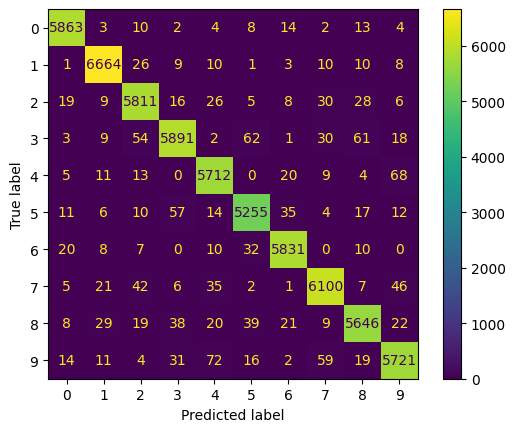

In [74]:
ConfusionMatrixDisplay.from_predictions(y_train,y_train_pred)